In [1]:
import simpy

data = [23, 45, 15, 0, 17]

def job1_sort(env):
    print(f"Job1 (Sort) started at time {env.now}")
    yield env.timeout(2)
    result = sorted(data)
    print(f"Job1 (Sort) completed at time {env.now}")
    print("Sorted array:", result)
    print()

def job2_smallest(env):
    print(f"Job2 (Search Smallest) started at time {env.now}")
    yield env.timeout(1)
    result = min(data)
    print(f"Job2 (Search Smallest) completed at time {env.now}")
    print("Smallest element:", result)
    print()

def job3_sum(env):
    print(f"Job3 (Sum) started at time {env.now}")
    yield env.timeout(1)
    result = sum(data)
    print(f"Job3 (Sum) completed at time {env.now}")
    print("Sum:", result)
    print()

def job4_mean(env):
    print(f"Job4 (Mean) started at time {env.now}")
    yield env.timeout(1)
    result = sum(data) / len(data)
    print(f"Job4 (Mean) completed at time {env.now}")
    print("Mean:", result)
    print()

cloudenv = simpy.Environment()

cloudenv.process(job1_sort(cloudenv))
cloudenv.process(job2_smallest(cloudenv))
cloudenv.process(job3_sum(cloudenv))
cloudenv.process(job4_mean(cloudenv))

cloudenv.run()

Job1 (Sort) started at time 0
Job2 (Search Smallest) started at time 0
Job3 (Sum) started at time 0
Job4 (Mean) started at time 0
Job2 (Search Smallest) completed at time 1
Smallest element: 0

Job3 (Sum) completed at time 1
Sum: 100

Job4 (Mean) completed at time 1
Mean: 20.0

Job1 (Sort) completed at time 2
Sorted array: [0, 15, 17, 23, 45]



In [2]:
import simpy

data = [23, 45, 15, 0, 17]

def job1_sort(env):
    print(f"Job1 (Sort) started at time {env.now}")
    yield env.timeout(2)
    result = sorted(data)
    print(f"Job1 (Sort) completed at time {env.now}")
    print("Sorted array:", result)
    print()

def job2_smallest(env):
    print(f"Job2 (Search Smallest) started at time {env.now}")
    yield env.timeout(1)
    result = min(data)
    print(f"Job2 (Search Smallest) completed at time {env.now}")
    print("Smallest element:", result)
    print()

def job3_sum(env):
    print(f"Job3 (Sum) started at time {env.now}")
    yield env.timeout(1)
    result = sum(data)
    print(f"Job3 (Sum) completed at time {env.now}")
    print("Sum:", result)
    print()

def job4_mean(env):
    print(f"Job4 (Mean) started at time {env.now}")
    yield env.timeout(1)
    result = sum(data) / len(data)
    print(f"Job4 (Mean) completed at time {env.now}")
    print("Mean:", result)
    print()

def job5_largest(env):
    print(f"Job5 (Search Largest) started at time {env.now}")
    yield env.timeout(1)
    result = max(data)
    print(f"Job5 (Search Largest) completed at time {env.now}")
    print("Largest element:", result)
    print()

def job6_reverse(env):
    print(f"Job6 (Reverse) started at time {env.now}")
    yield env.timeout(2)
    result = data[::-1]
    print(f"Job6 (Reverse) completed at time {env.now}")
    print("Reversed array:", result)
    print()

cloudenv = simpy.Environment()

cloudenv.process(job1_sort(cloudenv))
cloudenv.process(job2_smallest(cloudenv))
cloudenv.process(job3_sum(cloudenv))
cloudenv.process(job4_mean(cloudenv))
cloudenv.process(job5_largest(cloudenv))
cloudenv.process(job6_reverse(cloudenv))

cloudenv.run()

Job1 (Sort) started at time 0
Job2 (Search Smallest) started at time 0
Job3 (Sum) started at time 0
Job4 (Mean) started at time 0
Job5 (Search Largest) started at time 0
Job6 (Reverse) started at time 0
Job2 (Search Smallest) completed at time 1
Smallest element: 0

Job3 (Sum) completed at time 1
Sum: 100

Job4 (Mean) completed at time 1
Mean: 20.0

Job5 (Search Largest) completed at time 1
Largest element: 45

Job1 (Sort) completed at time 2
Sorted array: [0, 15, 17, 23, 45]

Job6 (Reverse) completed at time 2
Reversed array: [17, 0, 15, 45, 23]



Job1 (Sort) allocated to VM at time 0
Job2 (Smallest) allocated to VM at time 0
Job2 (Smallest) completed at time 1
Smallest element: 0

Job3 (Sum) allocated to VM at time 1
Job1 (Sort) completed at time 2
Sorted array: [0, 15, 17, 23, 45]

Job3 (Sum) completed at time 2
Sum: 100

Job4 (Mean) allocated to VM at time 2
Job5 (Search Largest) allocated to VM at time 2
Job4 (Mean) completed at time 3
Mean: 20.0

Job5 (Search Largest) completed at time 3
Largest element: 45

Job6 (Reverse) allocated to VM at time 3
Job6 (Reverse) completed at time 5
Reversed array: [17, 0, 15, 45, 23]


========== GANTT CHART DATA ==========
Job2 - Smallest: 0 -> 1
Job1 - Sort: 0 -> 2
Job3 - Sum: 1 -> 2
Job4 - Mean: 2 -> 3
Job5 - Largest: 2 -> 3
Job6 - Reverse: 3 -> 5


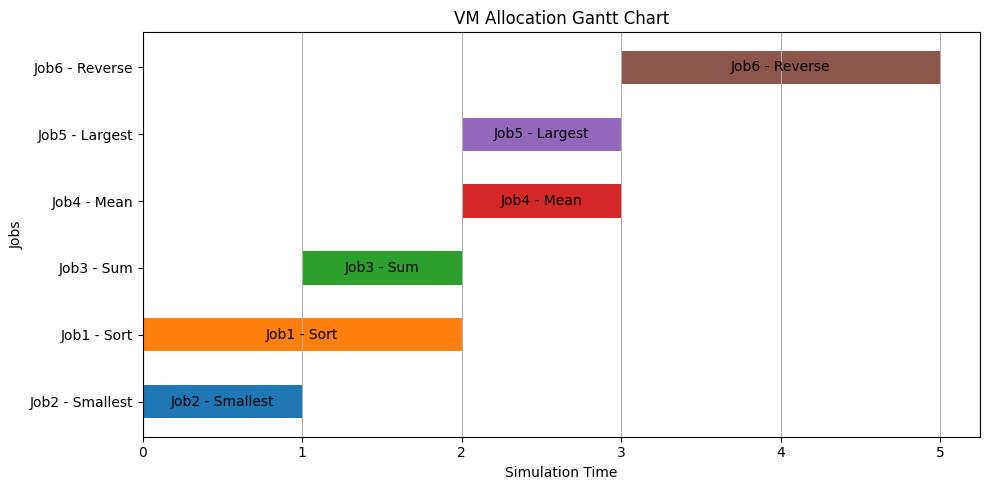

In [3]:
import simpy
import matplotlib.pyplot as plt

data = [23, 45, 15, 0, 17]
gantt_data = []

def job1_sort(env, vm):
    with vm.request() as request:
        yield request
        start = env.now
        print(f"Job1 (Sort) allocated to VM at time {start}")
        yield env.timeout(2)
        result = sorted(data)
        end = env.now
        gantt_data.append(("Job1 - Sort", start, end, "VM"))
        print(f"Job1 (Sort) completed at time {end}")
        print("Sorted array:", result)
        print()

def job2_smallest(env, vm):
    with vm.request() as request:
        yield request
        start = env.now
        print(f"Job2 (Smallest) allocated to VM at time {start}")
        yield env.timeout(1)
        result = min(data)
        end = env.now
        gantt_data.append(("Job2 - Smallest", start, end, "VM"))
        print(f"Job2 (Smallest) completed at time {end}")
        print("Smallest element:", result)
        print()

def job3_sum(env, vm):
    with vm.request() as request:
        yield request
        start = env.now
        print(f"Job3 (Sum) allocated to VM at time {start}")
        yield env.timeout(1)
        result = sum(data)
        end = env.now
        gantt_data.append(("Job3 - Sum", start, end, "VM"))
        print(f"Job3 (Sum) completed at time {end}")
        print("Sum:", result)
        print()

def job4_mean(env, vm):
    with vm.request() as request:
        yield request
        start = env.now
        print(f"Job4 (Mean) allocated to VM at time {start}")
        yield env.timeout(1)
        result = sum(data) / len(data)
        end = env.now
        gantt_data.append(("Job4 - Mean", start, end, "VM"))
        print(f"Job4 (Mean) completed at time {end}")
        print("Mean:", result)
        print()

def job5_largest(env, vm):
    with vm.request() as request:
        yield request
        start = env.now
        print(f"Job5 (Search Largest) allocated to VM at time {start}")
        yield env.timeout(1)
        result = max(data)
        end = env.now
        gantt_data.append(("Job5 - Largest", start, end, "VM"))
        print(f"Job5 (Search Largest) completed at time {end}")
        print("Largest element:", result)
        print()

def job6_reverse(env, vm):
    with vm.request() as request:
        yield request
        start = env.now
        print(f"Job6 (Reverse) allocated to VM at time {start}")
        yield env.timeout(2)
        result = data[::-1]
        end = env.now
        gantt_data.append(("Job6 - Reverse", start, end, "VM"))
        print(f"Job6 (Reverse) completed at time {end}")
        print("Reversed array:", result)
        print()

cloudenv = simpy.Environment()
vm = simpy.Resource(cloudenv, capacity=2)

cloudenv.process(job1_sort(cloudenv, vm))
cloudenv.process(job2_smallest(cloudenv, vm))
cloudenv.process(job3_sum(cloudenv, vm))
cloudenv.process(job4_mean(cloudenv, vm))
cloudenv.process(job5_largest(cloudenv, vm))
cloudenv.process(job6_reverse(cloudenv, vm))

cloudenv.run()

print("\n========== GANTT CHART DATA ==========")
for job, start, end, resource in gantt_data:
    print(f"{job}: {start} -> {end}")

plt.figure(figsize=(10, 5))

job_names = [item[0] for item in gantt_data]

for i, (job, start, end, resource) in enumerate(gantt_data):
    plt.barh(i, end - start, left=start, height=0.5)
    plt.text(start + (end - start) / 2, i, job, ha="center", va="center")

plt.yticks(range(len(job_names)), job_names)
plt.xlabel("Simulation Time")
plt.ylabel("Jobs")
plt.title("VM Allocation Gantt Chart")
plt.grid(axis="x")
plt.tight_layout()
plt.show()

Job1 - Sort allocated to VM1 at time 0
Job2 - Smallest allocated to VM2 at time 0
Job2 - Smallest completed at time 1
Result: 0
Waiting Time: 0
Turnaround Time: 1

Job3 - Sum allocated to VM2 at time 1
Job1 - Sort completed at time 2
Result: [0, 15, 17, 23, 45]
Waiting Time: 0
Turnaround Time: 2

Job3 - Sum completed at time 2
Result: 100
Waiting Time: 1
Turnaround Time: 2

Job4 - Mean allocated to VM1 at time 2
Job5 - Largest allocated to VM2 at time 2
Job4 - Mean completed at time 3
Result: 20.0
Waiting Time: 2
Turnaround Time: 3

Job5 - Largest completed at time 3
Result: 45
Waiting Time: 2
Turnaround Time: 3

Job6 - Reverse allocated to VM1 at time 3
Job6 - Reverse completed at time 5
Result: [17, 0, 15, 45, 23]
Waiting Time: 3
Turnaround Time: 5


========== JOB SUMMARY ==========
Job			VM	Arrival	Start	Completion	Waiting	Turnaround
Job1 - Sort	VM1	0	0	2		0	2
Job2 - Smallest	VM2	0	0	1		0	1
Job3 - Sum	VM2	0	1	2		1	2
Job4 - Mean	VM1	0	2	3		2	3
Job5 - Largest	VM2	0	2	3		2	3
Job6 - Re

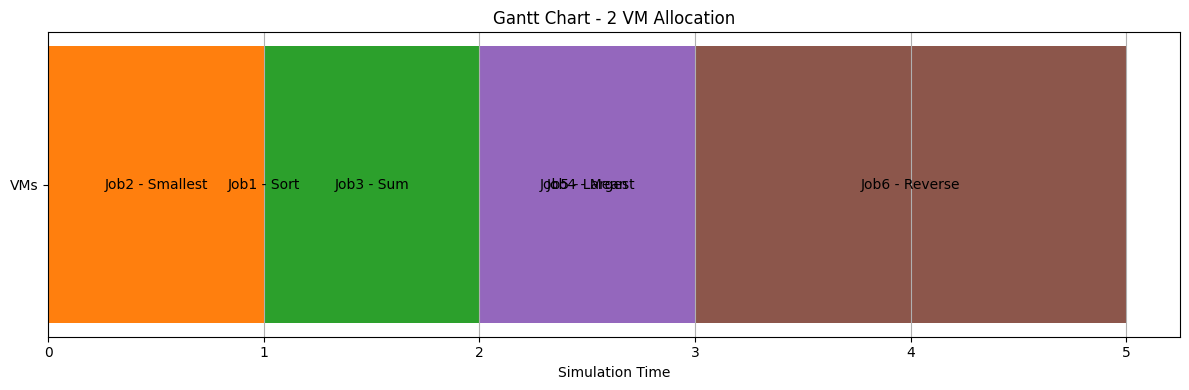

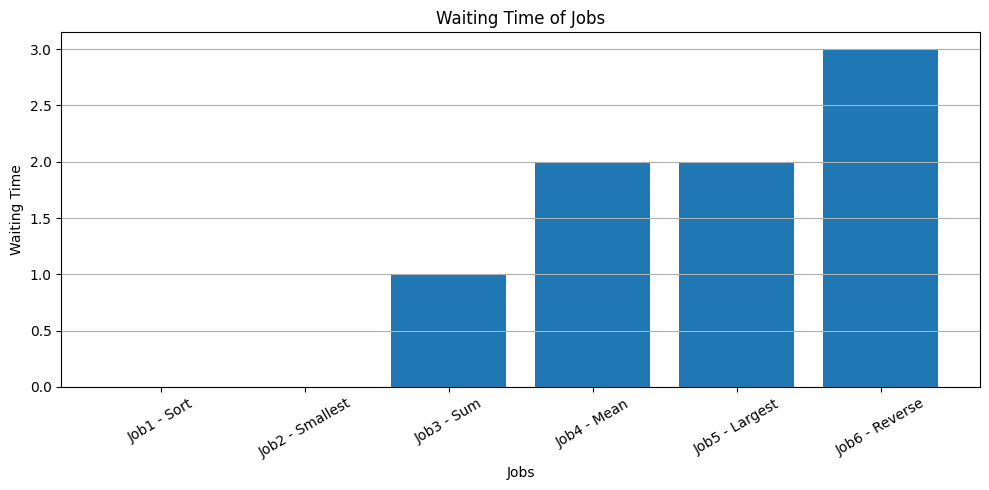

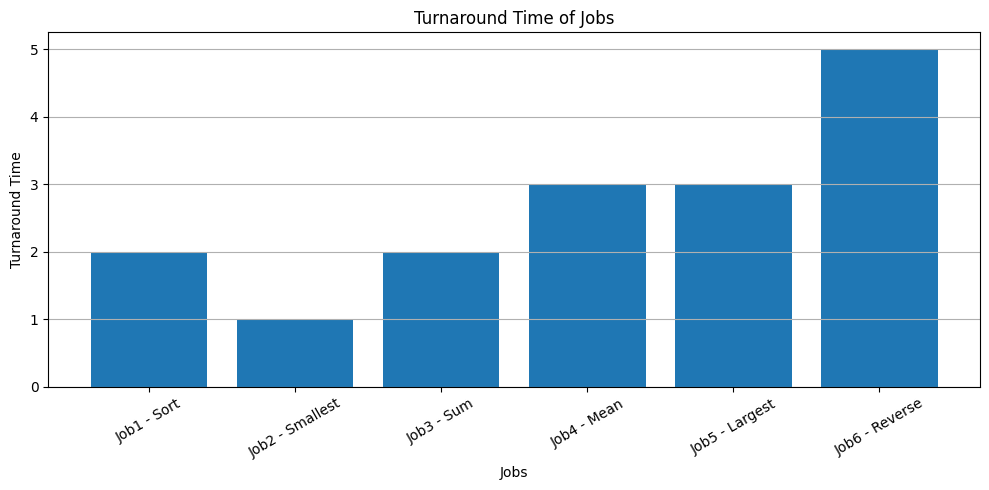

In [5]:
import simpy
import matplotlib.pyplot as plt

data = [23, 45, 15, 0, 17]

# Store job execution details
job_data = []

def run_job(env, vm, job_name, execution_time, operation):
    arrival = env.now

    with vm.request() as request:
        yield request

        start = env.now
        vm_number = request.resource.users.index(request) + 1

        print(f"{job_name} allocated to VM{vm_number} at time {start}")

        yield env.timeout(execution_time)

        result = operation(data)
        completion = env.now

        waiting_time = start - arrival
        turnaround_time = completion - arrival

        job_data.append({
            "job": job_name,
            "arrival": arrival,
            "start": start,
            "completion": completion,
            "waiting": waiting_time,
            "turnaround": turnaround_time,
            "vm": vm_number
        })

        print(f"{job_name} completed at time {completion}")
        print("Result:", result)
        print(f"Waiting Time: {waiting_time}")
        print(f"Turnaround Time: {turnaround_time}")
        print()


# Operations
def sort_array(data):
    return sorted(data)

def find_smallest(data):
    return min(data)

def find_sum(data):
    return sum(data)

def find_mean(data):
    return sum(data) / len(data)

def find_largest(data):
    return max(data)

def reverse_array(data):
    return data[::-1]


# Create Cloud Environment
cloudenv = simpy.Environment()

# Create 2 VMs
vm = simpy.Resource(cloudenv, capacity=2)


# Submit jobs
cloudenv.process(
    run_job(cloudenv, vm, "Job1 - Sort", 2, sort_array)
)

cloudenv.process(
    run_job(cloudenv, vm, "Job2 - Smallest", 1, find_smallest)
)

cloudenv.process(
    run_job(cloudenv, vm, "Job3 - Sum", 1, find_sum)
)

cloudenv.process(
    run_job(cloudenv, vm, "Job4 - Mean", 1, find_mean)
)

cloudenv.process(
    run_job(cloudenv, vm, "Job5 - Largest", 1, find_largest)
)

cloudenv.process(
    run_job(cloudenv, vm, "Job6 - Reverse", 2, reverse_array)
)


# Run simulation
cloudenv.run()


# Sort data by job number
job_data.sort(key=lambda x: int(x["job"].split(" - ")[0][3:]))


# Print summary
print("\n========== JOB SUMMARY ==========")
print("Job\t\t\tVM\tArrival\tStart\tCompletion\tWaiting\tTurnaround")

for job in job_data:
    print(
        f'{job["job"]}\tVM{job["vm"]}\t'
        f'{job["arrival"]}\t{job["start"]}\t'
        f'{job["completion"]}\t\t'
        f'{job["waiting"]}\t{job["turnaround"]}'
    )


# ==========================================================
# 1. SINGLE BARH GANTT CHART
# ==========================================================

plt.figure(figsize=(12, 4))

for i, job in enumerate(job_data):
    duration = job["completion"] - job["start"]

    plt.barh(
        0,
        duration,
        left=job["start"],
        height=0.5
    )

    plt.text(
        job["start"] + duration / 2,
        0,
        job["job"],
        ha="center",
        va="center"
    )

plt.xlabel("Simulation Time")
plt.yticks([0], ["VMs"])
plt.title("Gantt Chart - 2 VM Allocation")
plt.grid(axis="x")
plt.tight_layout()
plt.show()


# ==========================================================
# 2. WAITING TIME BAR CHART
# ==========================================================

jobs = [job["job"] for job in job_data]
waiting_times = [job["waiting"] for job in job_data]

plt.figure(figsize=(10, 5))

plt.bar(jobs, waiting_times)

plt.xlabel("Jobs")
plt.ylabel("Waiting Time")
plt.title("Waiting Time of Jobs")
plt.xticks(rotation=30)
plt.grid(axis="y")
plt.tight_layout()
plt.show()


# ==========================================================
# 3. TURNAROUND TIME BAR CHART
# ==========================================================

turnaround_times = [job["turnaround"] for job in job_data]

plt.figure(figsize=(10, 5))

plt.bar(jobs, turnaround_times)

plt.xlabel("Jobs")
plt.ylabel("Turnaround Time")
plt.title("Turnaround Time of Jobs")
plt.xticks(rotation=30)
plt.grid(axis="y")
plt.tight_layout()
plt.show()


Input Data : [23, 45, 15, 0, 17]

Job       Task                  VM        Start     Finish    Result
Job-1     Sort                  VM1       0         4         [0, 15, 17, 23, 45]
Job-2     Search Smallest       VM2       0         2         0
Job-3     Sum                   VM3       0         3         100
Job-4     Mean                  VM1       4         7         20.0
Job-5     Maximum               VM2       2         4         45
Job-6     Reverse Order         VM3       3         7         [17, 0, 15, 45, 23]

Makespan : 7
VM1 busy time = 7   utilization = 100.00 %
VM2 busy time = 4   utilization = 57.14 %
VM3 busy time = 7   utilization = 100.00 %


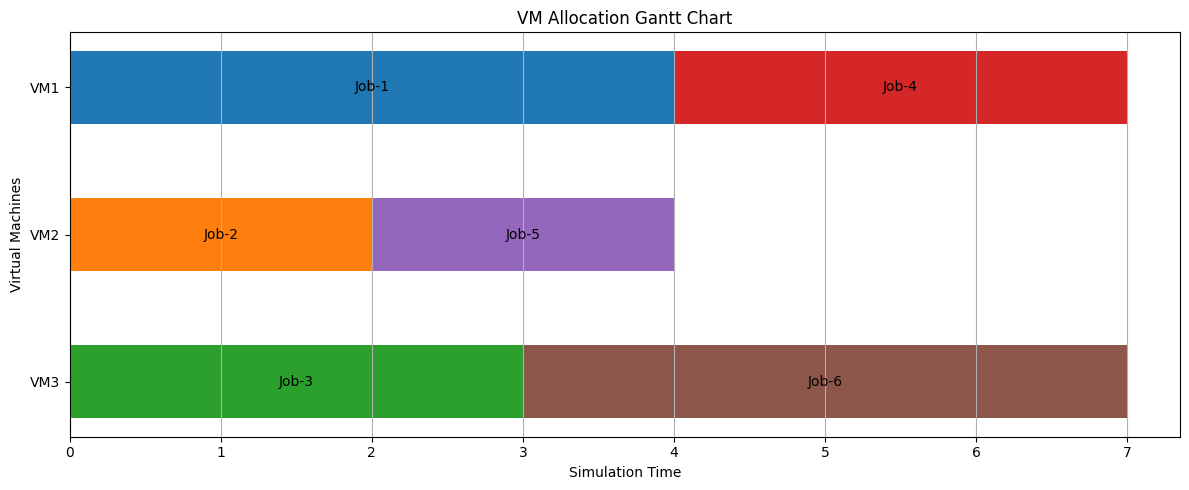

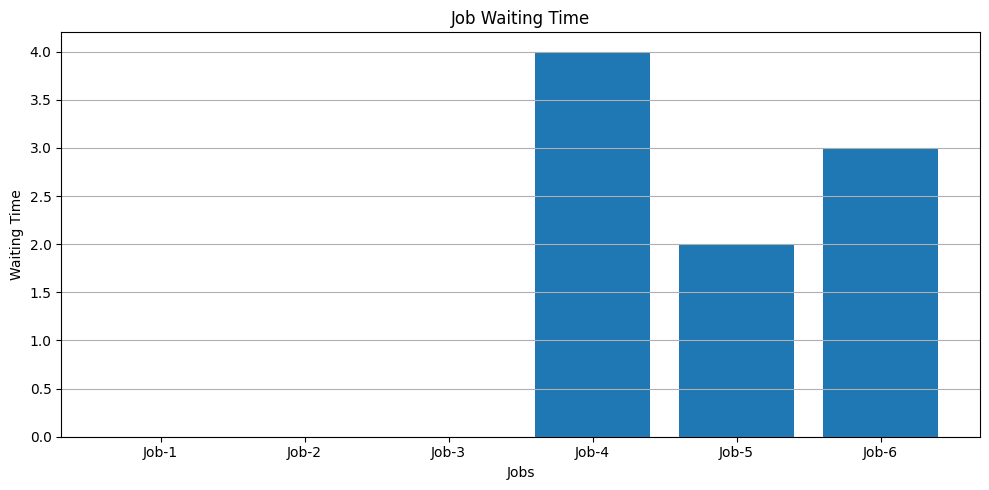

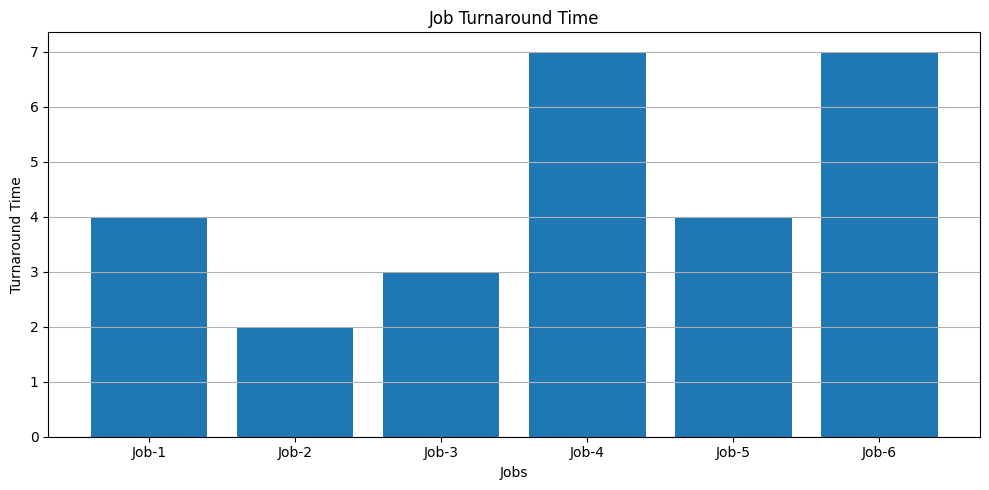

In [6]:
import simpy
import matplotlib.pyplot as plt

data = [23, 45, 15, 0, 17]

results = []

def run_job(env, vm, job, task, duration, operation):
    with vm.request() as request:
        yield request

        start = env.now
        result = operation(data)

        yield env.timeout(duration)

        finish = env.now

        results.append({
            "job": job,
            "task": task,
            "vm": vm.name,
            "start": start,
            "finish": finish,
            "result": result
        })


def sort_array(data):
    return sorted(data)


def smallest(data):
    return min(data)


def calculate_sum(data):
    return sum(data)


def mean(data):
    return sum(data) / len(data)


def maximum(data):
    return max(data)


def reverse(data):
    return data[::-1]


# Create Cloud Environment
cloudenv = simpy.Environment()

# Create 3 VMs
vm1 = simpy.Resource(cloudenv, capacity=1)
vm1.name = "VM1"

vm2 = simpy.Resource(cloudenv, capacity=1)
vm2.name = "VM2"

vm3 = simpy.Resource(cloudenv, capacity=1)
vm3.name = "VM3"


# Submit jobs to specific VMs
cloudenv.process(
    run_job(cloudenv, vm1, "Job-1", "Sort", 4, sort_array)
)

cloudenv.process(
    run_job(cloudenv, vm2, "Job-2", "Search Smallest", 2, smallest)
)

cloudenv.process(
    run_job(cloudenv, vm3, "Job-3", "Sum", 3, calculate_sum)
)

cloudenv.process(
    run_job(cloudenv, vm1, "Job-4", "Mean", 3, mean)
)

cloudenv.process(
    run_job(cloudenv, vm2, "Job-5", "Maximum", 2, maximum)
)

cloudenv.process(
    run_job(cloudenv, vm3, "Job-6", "Reverse Order", 4, reverse)
)


# Run simulation
cloudenv.run()


# Sort results according to job number
results.sort(key=lambda x: int(x["job"].split("-")[1]))


# ==========================================================
# PRINT OUTPUT
# ==========================================================

print("Input Data :", data)
print()

print("=" * 82)
print(f"{'Job':<10}{'Task':<22}{'VM':<10}{'Start':<10}{'Finish':<10}{'Result'}")
print("=" * 82)

for r in results:
    print(
        f"{r['job']:<10}"
        f"{r['task']:<22}"
        f"{r['vm']:<10}"
        f"{r['start']:<10}"
        f"{r['finish']:<10}"
        f"{r['result']}"
    )

print()


# ==========================================================
# MAKESPAN
# ==========================================================

makespan = max(r["finish"] for r in results)

print("Makespan :", makespan)


# ==========================================================
# VM BUSY TIME AND UTILIZATION
# ==========================================================

vm1_busy = sum(
    r["finish"] - r["start"]
    for r in results
    if r["vm"] == "VM1"
)

vm2_busy = sum(
    r["finish"] - r["start"]
    for r in results
    if r["vm"] == "VM2"
)

vm3_busy = sum(
    r["finish"] - r["start"]
    for r in results
    if r["vm"] == "VM3"
)

vm1_utilization = (vm1_busy / makespan) * 100
vm2_utilization = (vm2_busy / makespan) * 100
vm3_utilization = (vm3_busy / makespan) * 100

print(
    f"VM1 busy time = {vm1_busy}   "
    f"utilization = {vm1_utilization:.2f} %"
)

print(
    f"VM2 busy time = {vm2_busy}   "
    f"utilization = {vm2_utilization:.2f} %"
)

print(
    f"VM3 busy time = {vm3_busy}   "
    f"utilization = {vm3_utilization:.2f} %"
)


# ==========================================================
# GANTT CHART
# ==========================================================

plt.figure(figsize=(12, 5))

vm_positions = {
    "VM1": 2,
    "VM2": 1,
    "VM3": 0
}

for r in results:
    y = vm_positions[r["vm"]]
    duration = r["finish"] - r["start"]

    plt.barh(
        y,
        duration,
        left=r["start"],
        height=0.5
    )

    plt.text(
        r["start"] + duration / 2,
        y,
        r["job"],
        ha="center",
        va="center"
    )

plt.yticks(
    [0, 1, 2],
    ["VM3", "VM2", "VM1"]
)

plt.xlabel("Simulation Time")
plt.ylabel("Virtual Machines")
plt.title("VM Allocation Gantt Chart")

plt.grid(axis="x")
plt.tight_layout()
plt.show()


# ==========================================================
# WAITING TIME AND TURNAROUND TIME
# ==========================================================

waiting_times = []
turnaround_times = []
job_names = []

for r in results:
    arrival = 0
    waiting = r["start"] - arrival
    turnaround = r["finish"] - arrival

    job_names.append(r["job"])
    waiting_times.append(waiting)
    turnaround_times.append(turnaround)


# Waiting Time Chart
plt.figure(figsize=(10, 5))

plt.bar(job_names, waiting_times)

plt.xlabel("Jobs")
plt.ylabel("Waiting Time")
plt.title("Job Waiting Time")

plt.grid(axis="y")
plt.tight_layout()
plt.show()


# Turnaround Time Chart
plt.figure(figsize=(10, 5))

plt.bar(job_names, turnaround_times)

plt.xlabel("Jobs")
plt.ylabel("Turnaround Time")
plt.title("Job Turnaround Time")

plt.grid(axis="y")
plt.tight_layout()
plt.show()